# Qwen-27B Cross-Context Response-Code Subspaces

The alphabet replication found a stable L49 physical-result direction and causal L55 response components across A/B/C, X/Y/Z, and 1/2/3, but most independently estimated one-dimensional L55 pair axes did not reproduce.

[实验设置与运行说明](../../../docs/experiment_notes/05_appendix_content_and_encoding/1ce5282079688bbc.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 19 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 19 tracked cells.


## 1. Frozen cross-context subspace protocol


In [2]:
%%cell_progress 1/19 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/19 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/19 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   5%|5         | 1/19 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/19 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  11%|#         | 2/19 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/19 Lock the cross-context response-subspace protocol
cell_stage('Freezing supports, candidate dimensions, selection gates, and targets')
import hashlib
import json
from datetime import datetime, timezone

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
SEMANTIC_LAYER = 49
LABEL_LAYER = 55
CAPTURE_LAYERS = (SEMANTIC_LAYER, LABEL_LAYER)
SITE_SCOPE = 'final_prompt_token'

SEED = 20260909
CODEBOOKS = {
    'abc': ('A', 'B', 'C'),
    'xyz': ('X', 'Y', 'Z'),
    'digits': ('1', '2', '3'),
}
SEMANTICS = ('left', 'balanced', 'right')
ORDINAL_LABELS = ('L1', 'L2', 'L3')
ORDINAL_PAIRS = ('L1L2', 'L1L3', 'L2L3')
ORDINAL_TRANSITIONS = (
    'L1->L2', 'L2->L1', 'L1->L3',
    'L3->L1', 'L2->L3', 'L3->L2',
)
POSITION_TRANSITIONS = (
    'P1->P2', 'P2->P1', 'P1->P3',
    'P3->P1', 'P2->P3', 'P3->P2',
)
POSITION_FAVORED = ('P2->P1', 'P1->P3', 'P3->P2')
POSITION_REVERSE = ('P1->P2', 'P3->P1', 'P2->P3')
DONOR_TASKS = ('weight_more', 'weight_less')
CANDIDATE_DIMS = (1, 2, 4, 8)
DIRECTION_ORDERS_PER_PAIR = 2
TARGET_MODES = (
    'total', 'remove_1d', 'remove_selected', 'remove_random_selected',
)

EXPECTED_DIRECTION_FAMILIES = 32
DIRECTION_CALIBRATION_FAMILIES = 16
DIRECTION_CONFIRMATION_FAMILIES = 16
EXPECTED_DIRECTION_RECORDS_PER_FAMILY = (
    len(CODEBOOKS) * len(ORDINAL_PAIRS)
    * DIRECTION_ORDERS_PER_PAIR * len(DONOR_TASKS)
)
EXPECTED_DIRECTION_RECORDS = (
    EXPECTED_DIRECTION_FAMILIES * EXPECTED_DIRECTION_RECORDS_PER_FAMILY
)
EXPECTED_TARGET_FAMILIES = 24
TARGET_MAPPINGS = 6
TARGET_CELLS_PER_FAMILY = len(CODEBOOKS) * TARGET_MAPPINGS
TARGET_RECORDS_PER_FAMILY = TARGET_CELLS_PER_FAMILY * len(TARGET_MODES)
EXPECTED_TARGET_CELLS = EXPECTED_TARGET_FAMILIES * TARGET_CELLS_PER_FAMILY
EXPECTED_TARGET_RECORDS = EXPECTED_TARGET_FAMILIES * TARGET_RECORDS_PER_FAMILY

BOOTSTRAP_REPLICATES = 10000
SIGNFLIP_REPLICATES = 100000
ALPHA = 0.05
RELATIVE_ENERGY_GATE = 0.90
ENERGY_GAIN_CI_GATE = 0.02
SUBSPACE_OVERLAP_GATE = 0.10
TARGET_GAIN_SESOI = 0.05
POSITION_EQUIVALENCE_BOUND = 0.10
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
ORTHONORMAL_TOLERANCE = 1e-4

ALPHABET_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_response_code_alphabet_replication_v1'
)
ALPHABET_DECISION_PATH = ALPHABET_ROOT / 'analysis' / 'alphabet_decision.json'
ALPHABET_AUDIT_PATH = ALPHABET_ROOT / 'analysis' / 'robustness_audit.json'
ALPHABET_SUPPORT_PATH = ALPHABET_ROOT / 'support_lock.json'
ALPHABET_DIRECTION_SPLIT_PATH = ALPHABET_ROOT / 'direction_split.json'
ALPHABET_SHARD_DIR = ALPHABET_ROOT / 'family_shards'
PRIOR_AXIS_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_symmetric_code_axis_v1'
PRIOR_SEMANTIC_TENSOR_PATH = PRIOR_AXIS_ROOT / 'direction_tensors.pt'
DEPTH_SUPPORT_PATH = (
    PROJECT_ROOT / 'results' / 'semantic_label_depth_localization_v1'
    / 'depth_support.jsonl'
)
INVERSE_SCENE_DIR = (
    PROJECT_ROOT / 'results' / 'inverse_query_weight_route_specificity_v1'
    / 'rendered_scenes'
)
TARGET_SCENE_DIR = (
    PROJECT_ROOT / 'results' / 'targeted_shortcut_error_rescue_induction_v1'
    / 'rendered_scenes'
)

SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_cross_context_response_subspace_v1'
)
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SUPPORT_LOCK_PATH = SHARED_ROOT / 'support_lock.json'
DIRECTION_DELTA_DIR = SHARED_ROOT / 'direction_delta_shards'
SUBSPACE_TENSOR_PATH = SHARED_ROOT / 'selected_subspaces.pt'
SUBSPACE_SELECTION_PATH = SHARED_ROOT / 'subspace_selection.json'
TARGET_SHARD_DIR = SHARED_ROOT / 'target_shards'
ANALYSIS_DIR = SHARED_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (
    SHARED_ROOT, DIRECTION_DELTA_DIR, TARGET_SHARD_DIR,
    ANALYSIS_DIR, FIGURE_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'qwen27b-cross-context-response-subspace-1.0',
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'semantic_site': [SEMANTIC_LAYER, SITE_SCOPE],
    'response_site': [LABEL_LAYER, SITE_SCOPE],
    'codebooks': {key: list(value) for key, value in CODEBOOKS.items()},
    'candidate_dimensions': list(CANDIDATE_DIMS),
    'direction_design': (
        'Every physical direction family contributes every ordinal pair, '
        'two counterbalanced option orders, and both directions.'
    ),
    'selection_rule': (
        'Smallest dimension reaching 90% of held-out d8 energy, with '
        'family-bootstrap energy gain lower CI above 0.02 and calibration-'
        'confirmation mean squared principal cosine above 0.10.'
    ),
    'causal_test': (
        'On 24 held-out target families compare total L49 transport, '
        'removing d1, removing the frozen selected subspace, and removing '
        'a matched random subspace.'
    ),
    'positive_control': 'L1L2 one-dimensional attenuation',
    'bootstrap_unit': 'physical_family',
    'seed': SEED,
    'interpretation_limit': (
        'The experiment tests the downstream response interface only.'
    ),
}
canonical_protocol_identity = json.loads(json.dumps(
    protocol_identity, sort_keys=True
))
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == canonical_protocol_identity, (
        'Existing protocol differs. Use a new versioned output root.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': canonical_protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Direction delta records:', EXPECTED_DIRECTION_RECORDS)
print('Target cells / records:', EXPECTED_TARGET_CELLS, EXPECTED_TARGET_RECORDS)
print('Output:', SHARED_ROOT)


Lock the cross-context response-subspace protocol:  16%|#5        | 3/19 [00:00<?, ?cell/s]

Direction delta records: 1152
Target cells / records: 432 1728
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_cross_context_response_subspace_v1


In [6]:
%%cell_progress 5/19 Verify prerequisites and freeze independent supports
cell_stage('Loading prior result, direction split, semantic direction, and targets')
from collections import Counter, defaultdict

for required in (
    ALPHABET_DECISION_PATH, ALPHABET_AUDIT_PATH,
    ALPHABET_SUPPORT_PATH, ALPHABET_DIRECTION_SPLIT_PATH,
    ALPHABET_SHARD_DIR, PRIOR_SEMANTIC_TENSOR_PATH,
    DEPTH_SUPPORT_PATH, INVERSE_SCENE_DIR, TARGET_SCENE_DIR,
):
    assert Path(required).exists(), f'Missing prerequisite: {required}'

alphabet_decision = json.loads(
    ALPHABET_DECISION_PATH.read_text(encoding='utf-8')
)
alphabet_audit = json.loads(
    ALPHABET_AUDIT_PATH.read_text(encoding='utf-8')
)
assert alphabet_decision['primary_decision'] == (
    'one_or_more_codebook_axes_not_reliable'
)
assert alphabet_audit['families'] == 42
assert alphabet_audit['confirmation_families'] == EXPECTED_TARGET_FAMILIES
assert alphabet_audit['clean_clamp_error'] == 0
assert alphabet_audit['nonfinite_measurements'] == 0

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

direction_support = read_jsonl(DEPTH_SUPPORT_PATH)
assert len(direction_support) == EXPECTED_DIRECTION_FAMILIES
previous_direction_split = json.loads(
    ALPHABET_DIRECTION_SPLIT_PATH.read_text(encoding='utf-8')
)
calibration_ids = set(previous_direction_split['calibration_ids'])
confirmation_ids = set(previous_direction_split['confirmation_ids'])
assert len(calibration_ids) == DIRECTION_CALIBRATION_FAMILIES
assert len(confirmation_ids) == DIRECTION_CONFIRMATION_FAMILIES
assert not (calibration_ids & confirmation_ids)
assert calibration_ids | confirmation_ids == {
    row['family_id'] for row in direction_support
}

target_manifest = []
for path in sorted(ALPHABET_SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    if payload['analysis_split'] != 'confirmation':
        continue
    target_manifest.append({
        'family_id': str(payload['family_id']),
        'cohort': str(payload['cohort']),
        'counterbalance_phase': int(payload['counterbalance_phase']),
        'family': payload['family'],
    })
target_manifest.sort(key=lambda row: row['family_id'])
assert len(target_manifest) == EXPECTED_TARGET_FAMILIES

prior_tensors = torch.load(
    PRIOR_SEMANTIC_TENSOR_PATH, map_location='cpu', weights_only=False
)
assert prior_tensors['model_id'] == MODEL_ID
assert prior_tensors['revision'] == MODEL_REVISION
SEMANTIC_DIRECTION = prior_tensors['semantic_direction'].float()

def canonical_signature(stacks):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in stacks
    ))

direction_signatures = {
    canonical_signature(role['stacks'])
    for row in direction_support for role in row['roles'].values()
}
target_signatures = {
    canonical_signature(row['family']['roles']['base']['stacks'])
    for row in target_manifest
}
assert not (direction_signatures & target_signatures)

support_identity = {
    'schema_version': 'cross-context-subspace-support-1.0',
    'alphabet_decision_sha256': sha256_file(ALPHABET_DECISION_PATH),
    'alphabet_support_sha256': sha256_file(ALPHABET_SUPPORT_PATH),
    'direction_support_sha256': sha256_file(DEPTH_SUPPORT_PATH),
    'semantic_tensor_sha256': sha256_file(PRIOR_SEMANTIC_TENSOR_PATH),
    'calibration_ids': sorted(calibration_ids),
    'confirmation_ids': sorted(confirmation_ids),
    'target_rows': [{
        'family_id': row['family_id'],
        'cohort': row['cohort'],
        'counterbalance_phase': row['counterbalance_phase'],
        'diagnostic_cell': row['family']['diagnostic_cell'],
    } for row in target_manifest],
    'direction_target_geometry_overlap': 0,
}
if SUPPORT_LOCK_PATH.is_file():
    previous = json.loads(SUPPORT_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == support_identity
else:
    write_json_atomic(SUPPORT_LOCK_PATH, {
        'identity': support_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Direction calibration / confirmation:', len(calibration_ids), len(confirmation_ids))
print('Held-out target families:', len(target_manifest))
print('Target strata:', Counter(
    (row['cohort'], row['family']['diagnostic_cell'])
    for row in target_manifest
))


Verify prerequisites and freeze independent supports:  21%|##1       | 4/19 [00:00<?, ?cell/s]

Direction calibration / confirmation: 16 16
Held-out target families: 24
Target strata: Counter({('induction', 'weight_conflict'): 7, ('rescue', 'weight_conflict'): 7, ('induction', 'distance_conflict'): 6, ('rescue', 'distance_conflict'): 4})


In [7]:
%%cell_progress 6/19 Cache direction and target images on local SSD
cell_stage('Copying only required images from Drive')
import shutil

DIRECTION_RUNTIME_DIR = Path('/content/visualtorque_subspace_direction_images_v1')
TARGET_RUNTIME_DIR = Path('/content/visualtorque_subspace_target_images_v1')
DIRECTION_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
TARGET_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)
direction_files = sorted({
    role['image_filename']
    for row in direction_support for role in row['roles'].values()
})
target_files = sorted({
    row['family']['roles']['base']['image_filename']
    for row in target_manifest
})
for filename in tqdm(direction_files, desc='Caching direction images', unit='image'):
    source_path = INVERSE_SCENE_DIR / filename
    target_path = DIRECTION_RUNTIME_DIR / filename
    assert source_path.is_file(), source_path
    if not target_path.is_file() or target_path.stat().st_size != source_path.stat().st_size:
        shutil.copy2(source_path, target_path)
for filename in tqdm(target_files, desc='Caching target images', unit='image'):
    source_path = TARGET_SCENE_DIR / filename
    target_path = TARGET_RUNTIME_DIR / filename
    assert source_path.is_file(), source_path
    if not target_path.is_file() or target_path.stat().st_size != source_path.stat().st_size:
        shutil.copy2(source_path, target_path)
print('Cached direction / target images:', len(direction_files), len(target_files))


Cache direction and target images on local SSD:  26%|##6       | 5/19 [00:00<?, ?cell/s]

Caching direction images:   0%|          | 0/64 [00:00<?, ?image/s]

Caching target images:   0%|          | 0/24 [00:00<?, ?image/s]

Cached direction / target images: 64 24


## 2. Cross-context direction capture and frozen subspace selection


In [8]:
%%cell_progress 7/19 Load the pinned Qwen-27B decoder
cell_stage('Loading Qwen-27B and resolving decoder layers')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)
assert adapter.metadata['resolved_revision'] == MODEL_REVISION

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
print('Layer path:', LAYER_PATH)
print('Frozen sites:', SEMANTIC_LAYER, LABEL_LAYER)


Load the pinned Qwen-27B decoder:  32%|###1      | 6/19 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Frozen sites: 49 55


In [9]:
%%cell_progress 8/19 Define cross-context prompts and target counterbalance
cell_stage('Defining pair-complete direction prompts and held-out target prompts')
import itertools
import math
from visual_torque_toolkit.behavior import PromptCondition
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = {
    'outcome': 'Which way will the balance scale tip?',
    'weight_more': 'Which side has more total weight?',
    'weight_less': 'Which side has less total weight?',
}
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}
ALL_SEMANTIC_PERMUTATIONS = tuple(itertools.permutations(SEMANTICS))
ORDER_INDEX_PERMUTATIONS = tuple(itertools.permutations(range(3)))

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

def task_semantic(features, task):
    if task == 'outcome':
        value = int(features['net_torque'])
    elif task == 'weight_more':
        value = int(features['weight_score'])
    elif task == 'weight_less':
        value = -int(features['weight_score'])
    else:
        raise KeyError(task)
    return outcome(value)

def mapping_by_codebook(codebook_key, semantics):
    codes = CODEBOOKS[codebook_key]
    return tuple({
        'ordinal': index + 1,
        'label': codes[index],
        'semantic': semantic,
    } for index, semantic in enumerate(semantics))

def semantics_by_code(mapping, codebook_key):
    return tuple(
        next(item['semantic'] for item in mapping if item['label'] == code)
        for code in CODEBOOKS[codebook_key]
    )

def label_for(mapping, semantic):
    return next(item['label'] for item in mapping if item['semantic'] == semantic)

def ordinal_label(codebook_key, label):
    return f"L{CODEBOOKS[codebook_key].index(label) + 1}"

def ordinal_transition(codebook_key, source_label, desired_label):
    return f'{ordinal_label(codebook_key, source_label)}->{ordinal_label(codebook_key, desired_label)}'

def ordinal_pair_from_transition(transition):
    source_label, desired_label = transition.split('->')
    return ''.join(sorted((source_label, desired_label)))

def custom_prompt(task, mapping, line_order, codebook_key):
    item_by_label = {item['label']: item for item in mapping}
    options = '\n'.join(
        f"{label}. {SEMANTIC_TEXT[item_by_label[label]['semantic']]}"
        for label in line_order
    )
    valid = ', '.join(CODEBOOKS[codebook_key])
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT[task],
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one response '
        f'code and nothing else. Valid reply codes are: {valid}.',
    ])

def make_example(row, role, task, mapping, line_order, codebook_key,
                 name, image_root, split):
    features = role['features']
    codes = CODEBOOKS[codebook_key]
    semantics = semantics_by_code(mapping, codebook_key)
    gold = task_semantic(features, task)
    return BehaviorExample(
        example_id=f"subspace:{codebook_key}:{row['family_id']}:{name}",
        question_id=f"subspace_{codebook_key}_{row['family_id']}_{name}",
        scene_id=str(role['scene_id']),
        condition=PromptCondition.IMAGE_RULE,
        question_kind=task,
        variant='cross_context_response_subspace',
        split=split,
        problem_type='response_code_subspace',
        outcome=gold,
        net_torque=int(features['net_torque']),
        prompt=custom_prompt(task, mapping, line_order, codebook_key),
        image_path=(image_root / role['image_filename']).resolve(),
        labels=codes,
        option_text=tuple(SEMANTIC_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=codes[semantics.index(gold)],
        gold_semantic=gold,
    )

def pair_mapping(row, codebook_key, pair):
    low, high = pair[:2], pair[2:]
    low_index = ORDINAL_LABELS.index(low)
    high_index = ORDINAL_LABELS.index(high)
    remaining_index = next(
        index for index in range(3)
        if index not in (low_index, high_index)
    )
    flip = int(stable_key(f"pair-map:{row['family_id']}:{pair}")[:8], 16) % 2
    semantics = [None, None, None]
    semantics[low_index if not flip else high_index] = 'left'
    semantics[high_index if not flip else low_index] = 'right'
    semantics[remaining_index] = 'balanced'
    return mapping_by_codebook(codebook_key, tuple(semantics))

def direction_order_indices(row, pair):
    split = 'calibration' if row['family_id'] in calibration_ids else 'confirmation'
    rows = sorted(
        direction_support,
        key=lambda item: stable_key(f"order:{split}:{item['family_id']}"),
    )
    rows = [
        item for item in rows
        if (item['family_id'] in calibration_ids) == (split == 'calibration')
    ]
    rank = next(
        index for index, item in enumerate(rows)
        if item['family_id'] == row['family_id']
    )
    pair_offset = ORDINAL_PAIRS.index(pair) * 2
    base = (2 * rank + pair_offset) % 6
    return (base, (base + 1) % 6)

def line_order(codebook_key, order_index):
    codes = CODEBOOKS[codebook_key]
    return tuple(codes[index] for index in ORDER_INDEX_PERMUTATIONS[order_index])

def line_order_for_positions(codes, source_label, desired_label,
                             source_position, desired_position):
    order = [None, None, None]
    order[source_position - 1] = source_label
    order[desired_position - 1] = desired_label
    remaining = next(
        label for label in codes
        if label not in (source_label, desired_label)
    )
    order[next(index for index, value in enumerate(order) if value is None)] = remaining
    return tuple(order)

def target_metadata(row, codebook_key, mapping_index):
    family = row['family']
    features = family['roles']['base']['features']
    exact = str(features['outcome'])
    shortcut = str(features['strategy_predictions'][
        family['shortcut_type'] + '_only'
    ])
    desired = exact if row['cohort'] == 'rescue' else shortcut
    source_semantic = shortcut if row['cohort'] == 'rescue' else exact
    mapping = mapping_by_codebook(
        codebook_key, ALL_SEMANTIC_PERMUTATIONS[mapping_index]
    )
    source_label = label_for(mapping, source_semantic)
    desired_label = label_for(mapping, desired)
    transition = ordinal_transition(
        codebook_key, source_label, desired_label
    )
    transition_index = ORDINAL_TRANSITIONS.index(transition)
    position_transition = POSITION_TRANSITIONS[
        (transition_index + row['counterbalance_phase']) % 6
    ]
    source_position, desired_position = (
        int(value[1:]) for value in position_transition.split('->')
    )
    order = line_order_for_positions(
        CODEBOOKS[codebook_key], source_label, desired_label,
        source_position, desired_position,
    )
    return {
        'mapping': mapping,
        'line_order': order,
        'source_semantic': source_semantic,
        'desired_semantic': desired,
        'source_label': source_label,
        'desired_label': desired_label,
        'ordinal_transition': transition,
        'ordinal_pair': ordinal_pair_from_transition(transition),
        'position_transition': position_transition,
    }

preflight_rows = []
for codebook_key in CODEBOOKS:
    mapping = pair_mapping(direction_support[0], codebook_key, 'L1L2')
    example = make_example(
        direction_support[0], direction_support[0]['roles']['base'],
        'weight_more', mapping, CODEBOOKS[codebook_key], codebook_key,
        'preflight', DIRECTION_RUNTIME_DIR, 'preflight',
    )
    plan = adapter._candidate_plan(example)
    assert plan is not None, codebook_key
    _, token_by_label = plan
    token_ids = [int(token_by_label[label]) for label in CODEBOOKS[codebook_key]]
    assert len(set(token_ids)) == 3
    preflight_rows.append({
        'codebook': codebook_key,
        'labels': list(CODEBOOKS[codebook_key]),
        'token_ids': token_ids,
    })
display(pd.DataFrame(preflight_rows))


Define cross-context prompts and target counterbalance:  37%|###6      | 7/19 [00:00<?, ?cell/s]

,codebook,labels,token_ids
0,abc,"[A, B, C]","[32, 33, 34]"
1,xyz,"[X, Y, Z]","[55, 56, 57]"
2,digits,"[1, 2, 3]","[16, 17, 18]"


In [10]:
%%cell_progress 9/19 Define hidden-state capture and subspace intervention helpers
cell_stage('Defining final-token capture, orthogonal projection, and scoring')

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(output.last_hidden_state):
        hidden = output.last_hidden_state
    else:
        raise TypeError(type(output).__name__)
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('Response codes must be single-token candidates.')
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )), fixed_prefix,
    )
    return {'examples': examples, 'inputs': inputs, 'token_by_label': token_by_label}

def final_mask(prepared):
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    mask = torch.zeros_like(attention)
    mask[int(torch.where(attention)[0][-1])] = True
    return mask

def score_record(prepared, logits):
    example = prepared['examples'][0]
    logprobs = torch.log_softmax(logits[0, -1, :].float(), dim=-1)
    scores = [
        float(logprobs[prepared['token_by_label'][label]].detach().cpu())
        for label in example.labels
    ]
    maximum = max(scores)
    weights = [math.exp(value - maximum) for value in scores]
    probabilities = [value / sum(weights) for value in weights]
    predicted = int(np.argmax(scores))
    return {
        'candidate_labels': list(example.labels),
        'candidate_semantics': list(example.option_semantics),
        'candidate_logprobs': scores,
        'candidate_probabilities': probabilities,
        'predicted_label': example.labels[predicted],
        'predicted_semantic': example.option_semantics[predicted],
        'gold_label': example.gold_label,
        'gold_semantic': example.gold_semantic,
    }

def capture_selected_hidden(example, layers):
    prepared = prepare_examples([example])
    mask = final_mask(prepared)
    captured = {}
    handles = []
    for layer_index in layers:
        def hook(_module, _inputs, output, layer_index=layer_index):
            captured[layer_index] = output_hidden_tensor(
                output
            ).detach().cpu()[0][mask].float().clone()
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_record(prepared, output.logits), captured

def selected_norm(tensor):
    return float(torch.linalg.vector_norm(tensor.float()))

def unit_direction(tensor):
    norm = selected_norm(tensor)
    assert norm > 0
    return tensor.float() / norm

def orthonormal_basis(matrix, dimension):
    matrix = matrix.float().reshape(matrix.shape[0], -1)
    _, _, vh = torch.linalg.svd(matrix, full_matrices=False)
    basis = vh[:dimension].contiguous()
    identity = basis @ basis.T
    assert float(torch.max(torch.abs(
        identity - torch.eye(dimension)
    ))) < ORTHONORMAL_TOLERANCE
    return basis

def random_basis(reference_basis, key):
    dimension, hidden = reference_basis.shape
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    matrix = torch.randn(hidden, dimension, generator=generator)
    q, _ = torch.linalg.qr(matrix, mode='reduced')
    return q.T.contiguous()

def projection_component(delta, basis):
    basis = basis.float()
    return (delta.float() @ basis.T) @ basis

def captured_energy(delta, basis):
    numerator = torch.sum(projection_component(delta, basis) ** 2)
    denominator = torch.sum(delta.float() ** 2)
    assert float(denominator) > 0
    return float(numerator / denominator)

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

def score_subspace_condition(example, clean_l55, condition):
    prepared = prepare_examples([example])
    mask = final_mask(prepared)
    measurements = {}

    def l49_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        current = mask.to(hidden.device)
        payload = condition['l49_payload'].to(hidden.device, hidden.dtype)
        modified = hidden.clone()
        modified[0, current] = hidden[0, current] + payload
        return replace_output_hidden(output, modified)

    def l55_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        current = mask.to(hidden.device)
        clean = clean_l55.to(hidden.device, torch.float32)
        basis_1d = condition['basis_1d'].to(hidden.device, torch.float32)
        basis_selected = condition['basis_selected'].to(hidden.device, torch.float32)
        basis_random = condition['basis_random'].to(hidden.device, torch.float32)
        delta = hidden[0, current].float() - clean
        component_1d = projection_component(delta, basis_1d)
        component_selected = projection_component(delta, basis_selected)
        random_projection = projection_component(delta, basis_random)
        selected_component_norm = torch.linalg.vector_norm(component_selected)
        random_projection_norm = torch.linalg.vector_norm(random_projection)
        component_random = random_projection * (
            selected_component_norm / torch.clamp(
                random_projection_norm, min=1e-12
            )
        )
        mode = condition['mode']
        if mode == 'total':
            selected = hidden[0, current].float()
        elif mode == 'remove_1d':
            selected = hidden[0, current].float() - component_1d
        elif mode == 'remove_selected':
            selected = hidden[0, current].float() - component_selected
        elif mode == 'remove_random_selected':
            selected = hidden[0, current].float() - component_random
        elif mode == 'clean_clamp':
            selected = clean
        else:
            raise ValueError(mode)
        modified = hidden.clone()
        modified[0, current] = selected.to(hidden.dtype)
        measurements.update({
            'l55_delta_norm': selected_norm(delta),
            'component_1d_norm': selected_norm(component_1d),
            'component_selected_norm': selected_norm(component_selected),
            'component_random_norm': selected_norm(component_random),
        })
        return replace_output_hidden(output, modified)

    handles = [
        DECODER_LAYERS[SEMANTIC_LAYER].register_forward_hook(l49_hook),
        DECODER_LAYERS[LABEL_LAYER].register_forward_hook(l55_hook),
    ]
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    record = score_record(prepared, output.logits)
    record.update({
        key: value for key, value in condition.items()
        if key not in (
            'l49_payload', 'basis_1d', 'basis_selected', 'basis_random'
        )
    })
    record.update(measurements)
    record['patched_tokens'] = int(mask.sum())
    return record

print('Capture and subspace intervention helpers ready.')


Define hidden-state capture and subspace intervention helpers:  42%|####2     | 8/19 [00:00<?, ?cell/s]

Capture and subspace intervention helpers ready.


In [11]:
%%cell_progress 10/19 Capture pair-complete cross-context direction deltas
cell_stage('Capturing resumable physical-family delta shards')

direction_capture_identity = {
    'schema_version': 'cross-context-direction-capture-1.0',
    'protocol_identity': canonical_protocol_identity,
    'support_identity': support_identity,
    'resolved_revision': adapter.metadata['resolved_revision'],
    'records_per_family': EXPECTED_DIRECTION_RECORDS_PER_FAMILY,
}
DIRECTION_CAPTURE_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(direction_capture_identity, sort_keys=True).encode('utf-8')
).hexdigest()

completed_direction_ids = set()
for path in sorted(DIRECTION_DELTA_DIR.glob('*.pt')):
    payload = torch.load(path, map_location='cpu', weights_only=False)
    assert payload['capture_identity_sha256'] == DIRECTION_CAPTURE_SHA256
    assert len(payload['records']) == EXPECTED_DIRECTION_RECORDS_PER_FAMILY
    completed_direction_ids.add(str(payload['family_id']))
print('Direction families completed:', len(completed_direction_ids), '/', EXPECTED_DIRECTION_FAMILIES)

remaining = [
    row for row in direction_support
    if row['family_id'] not in completed_direction_ids
]
progress = tqdm(
    total=len(remaining) * EXPECTED_DIRECTION_RECORDS_PER_FAMILY,
    desc='Cross-context direction deltas', unit='delta',
)
for row in remaining:
    split = 'calibration' if row['family_id'] in calibration_ids else 'confirmation'
    records = []
    for codebook_key in CODEBOOKS:
        for pair in ORDINAL_PAIRS:
            mapping = pair_mapping(row, codebook_key, pair)
            for order_index in direction_order_indices(row, pair):
                order = line_order(codebook_key, order_index)
                for donor_task in DONOR_TASKS:
                    examples = {}
                    for role_name in ('base', 'aligned_source'):
                        examples[role_name] = make_example(
                            row, row['roles'][role_name], donor_task,
                            mapping, order, codebook_key,
                            f'{pair}__o{order_index}__{donor_task}__{role_name}',
                            DIRECTION_RUNTIME_DIR, split,
                        )
                    _, base_hidden = capture_selected_hidden(
                        examples['base'], CAPTURE_LAYERS
                    )
                    _, source_hidden = capture_selected_hidden(
                        examples['aligned_source'], CAPTURE_LAYERS
                    )
                    base_semantic = task_semantic(
                        row['roles']['base']['features'], donor_task
                    )
                    source_semantic = task_semantic(
                        row['roles']['aligned_source']['features'], donor_task
                    )
                    assert {base_semantic, source_semantic} == {'left', 'right'}
                    source_label = label_for(mapping, base_semantic)
                    desired_label = label_for(mapping, source_semantic)
                    transition = ordinal_transition(
                        codebook_key, source_label, desired_label
                    )
                    assert ordinal_pair_from_transition(transition) == pair
                    source_position = order.index(source_label) + 1
                    desired_position = order.index(desired_label) + 1
                    records.append({
                        'family_id': row['family_id'],
                        'split': split,
                        'codebook': codebook_key,
                        'pair': pair,
                        'transition': transition,
                        'order_index': int(order_index),
                        'position_transition': f'P{source_position}->P{desired_position}',
                        'donor_task': donor_task,
                        'l55_delta': (
                            source_hidden[LABEL_LAYER] - base_hidden[LABEL_LAYER]
                        ).to(torch.float16).cpu(),
                        'l49_delta': (
                            source_hidden[SEMANTIC_LAYER] - base_hidden[SEMANTIC_LAYER]
                        ).to(torch.float16).cpu(),
                    })
                    progress.update(1)
                    progress.set_postfix_str(
                        f"{row['family_id']} | {codebook_key} | {pair}"
                    )
    assert len(records) == EXPECTED_DIRECTION_RECORDS_PER_FAMILY
    payload = {
        'schema_version': 'cross-context-direction-family-shard-1.0',
        'capture_identity_sha256': DIRECTION_CAPTURE_SHA256,
        'family_id': row['family_id'],
        'split': split,
        'records': records,
    }
    final_path = DIRECTION_DELTA_DIR / f"{row['family_id']}.pt"
    temporary = final_path.with_suffix('.pt.tmp')
    torch.save(payload, temporary)
    temporary.replace(final_path)
    torch.cuda.empty_cache()
progress.close()

direction_shards = sorted(DIRECTION_DELTA_DIR.glob('*.pt'))
assert len(direction_shards) == EXPECTED_DIRECTION_FAMILIES
assert sum(
    len(torch.load(path, map_location='cpu', weights_only=False)['records'])
    for path in direction_shards
) == EXPECTED_DIRECTION_RECORDS
print('Direction capture complete:', EXPECTED_DIRECTION_RECORDS, 'delta records')


Capture pair-complete cross-context direction deltas:  47%|####7     | 9/19 [00:00<?, ?cell/s]

Direction families completed: 0 / 32


Cross-context direction deltas:   0%|          | 0/1152 [00:00<?, ?delta/s]

Direction capture complete: 1152 delta records


In [12]:
%%cell_progress 11/19 Fit, validate, and freeze the minimal response subspaces
cell_stage('Comparing 1D, 2D, 4D, and 8D subspaces on disjoint families')

def bootstrap_summary(values, key, replicates=BOOTSTRAP_REPLICATES):
    array = np.asarray(values, dtype=float)
    array = array[np.isfinite(array)]
    generator = np.random.default_rng(
        int(stable_key(f'bootstrap:{key}')[:16], 16) % (2**63 - 1)
    )
    draws = generator.choice(
        array, size=(replicates, len(array)), replace=True
    ).mean(axis=1)
    return {
        'n': int(len(array)),
        'mean': float(array.mean()),
        'ci_low': float(np.quantile(draws, ALPHA / 2)),
        'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
    }

direction_records = []
for path in sorted(DIRECTION_DELTA_DIR.glob('*.pt')):
    direction_records.extend(torch.load(
        path, map_location='cpu', weights_only=False
    )['records'])
assert len(direction_records) == EXPECTED_DIRECTION_RECORDS

grouped = defaultdict(list)
for record in direction_records:
    grouped[(record['split'], record['codebook'], record['pair'])].append(record)
assert all(
    (split, codebook_key, pair) in grouped
    for split in ('calibration', 'confirmation')
    for codebook_key in CODEBOOKS
    for pair in ORDINAL_PAIRS
)

BASES_BY_DIM = {key: {} for key in CODEBOOKS}
geometry_rows = []
family_energy_rows = []
for codebook_key in CODEBOOKS:
    for pair in ORDINAL_PAIRS:
        calibration = grouped[('calibration', codebook_key, pair)]
        confirmation = grouped[('confirmation', codebook_key, pair)]
        calibration_matrix = torch.cat([
            unit_direction(record['l55_delta']) for record in calibration
        ], dim=0)
        confirmation_matrix = torch.cat([
            unit_direction(record['l55_delta']) for record in confirmation
        ], dim=0)
        assert calibration_matrix.shape[0] == 64
        assert confirmation_matrix.shape[0] == 64
        BASES_BY_DIM[codebook_key][pair] = {}
        calibration_full_basis = orthonormal_basis(
            calibration_matrix, max(CANDIDATE_DIMS)
        )
        confirmation_full_basis = orthonormal_basis(
            confirmation_matrix, max(CANDIDATE_DIMS)
        )
        for dimension in CANDIDATE_DIMS:
            calibration_basis = calibration_full_basis[:dimension].contiguous()
            confirmation_basis = confirmation_full_basis[:dimension].contiguous()
            BASES_BY_DIM[codebook_key][pair][dimension] = calibration_basis
            singular_values = torch.linalg.svdvals(
                calibration_basis @ confirmation_basis.T
            )
            overlap = float(torch.mean(singular_values ** 2))
            random = random_basis(
                calibration_basis,
                f'direction-random:{codebook_key}:{pair}:d{dimension}',
            )
            by_family = defaultdict(list)
            for record in confirmation:
                delta = unit_direction(record['l55_delta'])
                observed = captured_energy(delta, calibration_basis)
                random_value = captured_energy(delta, random)
                by_family[record['family_id']].append(
                    (observed, random_value)
                )
            family_gains = []
            family_energies = []
            for family_id, values in by_family.items():
                observed = float(np.mean([value[0] for value in values]))
                random_value = float(np.mean([value[1] for value in values]))
                family_gains.append(observed - random_value)
                family_energies.append(observed)
                family_energy_rows.append({
                    'family_id': family_id,
                    'codebook': codebook_key,
                    'pair': pair,
                    'dimension': dimension,
                    'heldout_energy': observed,
                    'random_energy': random_value,
                    'energy_gain': observed - random_value,
                })
            gain_summary = bootstrap_summary(
                family_gains, f'geometry:{codebook_key}:{pair}:d{dimension}'
            )
            geometry_rows.append({
                'codebook': codebook_key,
                'pair': pair,
                'dimension': dimension,
                'heldout_energy': float(np.mean(family_energies)),
                'random_energy': float(np.mean([
                    row['random_energy'] for row in family_energy_rows
                    if row['codebook'] == codebook_key
                    and row['pair'] == pair
                    and row['dimension'] == dimension
                ])),
                'energy_gain': gain_summary['mean'],
                'energy_gain_ci_low': gain_summary['ci_low'],
                'energy_gain_ci_high': gain_summary['ci_high'],
                'mean_squared_principal_cosine': overlap,
                'minimum_principal_cosine': float(singular_values.min()),
            })

geometry_frame = pd.DataFrame(geometry_rows)
family_energy_frame = pd.DataFrame(family_energy_rows)
selection_rows = []
SELECTED_DIM = {key: {} for key in CODEBOOKS}
SELECTION_PASS = {key: {} for key in CODEBOOKS}
for (codebook_key, pair), current in geometry_frame.groupby(['codebook', 'pair']):
    current = current.sort_values('dimension').copy()
    d8_energy = float(current[current['dimension'] == 8]['heldout_energy'].iloc[0])
    current['relative_to_d8'] = current['heldout_energy'] / max(d8_energy, 1e-12)
    eligible = current[
        (current['relative_to_d8'] >= RELATIVE_ENERGY_GATE)
        & (current['energy_gain_ci_low'] > ENERGY_GAIN_CI_GATE)
        & (current['mean_squared_principal_cosine'] > SUBSPACE_OVERLAP_GATE)
    ]
    if len(eligible):
        selected_dimension = int(eligible['dimension'].min())
        selection_pass = True
    else:
        selected_dimension = 8
        selection_pass = False
    SELECTED_DIM[codebook_key][pair] = selected_dimension
    SELECTION_PASS[codebook_key][pair] = selection_pass
    for _, row in current.iterrows():
        selection_rows.append({
            **row.to_dict(),
            'relative_to_d8': float(row['relative_to_d8']),
            'selected': int(row['dimension']) == selected_dimension,
            'selection_pass': selection_pass,
        })
geometry_frame = pd.DataFrame(selection_rows)

subspace_payload = {
    'schema_version': 'cross-context-response-subspaces-1.0',
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'bases_by_dim': {
        codebook_key: {
            pair: {
                str(dimension): basis.cpu()
                for dimension, basis in BASES_BY_DIM[codebook_key][pair].items()
            }
            for pair in ORDINAL_PAIRS
        }
        for codebook_key in CODEBOOKS
    },
    'selected_dim': SELECTED_DIM,
    'selection_pass': SELECTION_PASS,
}
selection_identity = {
    'schema_version': 'cross-context-subspace-selection-identity-1.0',
    'protocol_identity': canonical_protocol_identity,
    'support_identity': support_identity,
    'direction_capture_sha256': DIRECTION_CAPTURE_SHA256,
    'selected_without_target_outputs': True,
}
if SUBSPACE_SELECTION_PATH.is_file() and SUBSPACE_TENSOR_PATH.is_file():
    selection_payload = json.loads(
        SUBSPACE_SELECTION_PATH.read_text(encoding='utf-8')
    )
    assert selection_payload['identity'] == selection_identity
    assert selection_payload['subspace_tensor_sha256'] == sha256_file(
        SUBSPACE_TENSOR_PATH
    )
    cached_subspaces = torch.load(
        SUBSPACE_TENSOR_PATH, map_location='cpu', weights_only=False
    )
    SELECTED_DIM = selection_payload['selected_dim']
    SELECTION_PASS = selection_payload['selection_pass']
    BASES_BY_DIM = {
        codebook_key: {
            pair: {
                int(dimension): basis.float()
                for dimension, basis in cached_subspaces[
                    'bases_by_dim'
                ][codebook_key][pair].items()
            }
            for pair in ORDINAL_PAIRS
        }
        for codebook_key in CODEBOOKS
    }
    geometry_frame = pd.DataFrame(selection_payload['geometry'])
    SUBSPACE_TENSOR_SHA256 = selection_payload['subspace_tensor_sha256']
    print('Loaded the existing frozen subspace library.')
else:
    if SUBSPACE_SELECTION_PATH.is_file() != SUBSPACE_TENSOR_PATH.is_file():
        print('Incomplete subspace cache detected; rebuilding it atomically.')
    temporary = SUBSPACE_TENSOR_PATH.with_suffix('.pt.tmp')
    torch.save(subspace_payload, temporary)
    temporary.replace(SUBSPACE_TENSOR_PATH)
    SUBSPACE_TENSOR_SHA256 = sha256_file(SUBSPACE_TENSOR_PATH)
    selection_payload = {
        'schema_version': 'cross-context-subspace-selection-1.0',
        'identity': selection_identity,
        'subspace_tensor_sha256': SUBSPACE_TENSOR_SHA256,
        'selected_dim': SELECTED_DIM,
        'selection_pass': SELECTION_PASS,
        'geometry': geometry_frame.to_dict(orient='records'),
    }
    write_json_atomic(SUBSPACE_SELECTION_PATH, selection_payload)
geometry_frame.to_csv(ANALYSIS_DIR / 'subspace_geometry.csv', index=False)
family_energy_frame.to_csv(
    ANALYSIS_DIR / 'heldout_direction_family_energy.csv', index=False
)
display(geometry_frame.round(4))
display(pd.DataFrame(SELECTED_DIM).T.rename_axis('codebook'))
print('Selection pass:', SELECTION_PASS)


Fit, validate, and freeze the minimal response subspaces:  53%|#####2    | 10/19 [00:00<?, ?cell/s]

,codebook,pair,dimension,heldout_energy,random_energy,energy_gain,energy_gain_ci_low,energy_gain_ci_high,mean_squared_principal_cosine,minimum_principal_cosine,relative_to_d8,selected,selection_pass
0,abc,L1L2,1,0.1515,0.0003,0.1513,0.0805,0.2316,0.3496,0.5912,0.2700,False,True
1,abc,L1L2,2,0.3078,0.0004,0.3073,0.2139,0.4071,0.6381,0.6019,0.5484,False,True
2,abc,L1L2,4,0.5000,0.0013,0.4986,0.4134,0.5822,0.8606,0.8350,0.8910,False,True
3,abc,L1L2,8,0.5611,0.0011,0.5600,0.4739,0.6439,0.5544,0.2997,1.0000,True,True
4,abc,L1L3,1,0.1274,0.0001,0.1273,0.0888,0.1716,0.0702,0.2649,0.2224,False,True
5,abc,L1L3,2,0.2635,0.0004,0.2631,0.2027,0.3251,0.4154,0.5457,0.4599,False,True
6,abc,L1L3,4,0.4822,0.0009,0.4812,0.4105,0.5476,0.7694,0.7007,0.8416,False,True
7,abc,L1L3,8,0.5729,0.0017,0.5712,0.5062,0.6327,0.5731,0.1550,1.0000,True,True
8,abc,L2L3,1,0.0765,0.0002,0.0763,0.0317,0.1295,0.0186,0.1364,0.1437,False,True
9,abc,L2L3,2,0.2120,0.0002,0.2117,0.1554,0.2771,0.3756,0.3143,0.3984,False,True


,L1L2,L1L3,L2L3
codebook,,,
abc,8,8,8
xyz,8,8,8
digits,8,8,8


Selection pass: {'abc': {'L1L2': True, 'L1L3': True, 'L2L3': True}, 'xyz': {'L1L2': True, 'L1L3': True, 'L2L3': True}, 'digits': {'L1L2': True, 'L1L3': True, 'L2L3': True}}


In [13]:
%%cell_progress 12/19 Build and audit the frozen held-out target factorial
cell_stage('Reconstructing the exact 24-family confirmation design')

def make_target_example(row, codebook_key, mapping_index, metadata):
    return make_example(
        row, row['family']['roles']['base'], 'outcome',
        metadata['mapping'], metadata['line_order'], codebook_key,
        f'target__m{mapping_index}', TARGET_RUNTIME_DIR,
        'heldout_target_confirmation',
    )

target_design_rows = []
for row in target_manifest:
    for codebook_key in CODEBOOKS:
        for mapping_index in range(6):
            metadata = target_metadata(row, codebook_key, mapping_index)
            target_design_rows.append({
                'family_id': row['family_id'],
                'codebook': codebook_key,
                'mapping_index': mapping_index,
                'pair': metadata['ordinal_pair'],
                'transition': metadata['ordinal_transition'],
                'position_transition': metadata['position_transition'],
            })
target_design_frame = pd.DataFrame(target_design_rows)
assert len(target_design_frame) == EXPECTED_TARGET_CELLS
for codebook_key in CODEBOOKS:
    current = target_design_frame[
        target_design_frame['codebook'] == codebook_key
    ]
    assert set(current.groupby([
        'transition', 'position_transition'
    ]).size()) == {4}
    assert set(current.groupby('pair').size()) == {48}
target_design_frame.to_csv(
    ANALYSIS_DIR / 'target_factorial_design.csv', index=False
)
print('Held-out target design is exactly balanced:', len(target_design_frame), 'cells')


Build and audit the frozen held-out target factorial:  58%|#####7    | 11/19 [00:00<?, ?cell/s]

Held-out target design is exactly balanced: 432 cells


In [14]:
%%cell_progress 13/19 Run basis, physics, token, and parity smoke tests
cell_stage('Checking frozen dimensions and exact clean-state replay')

for codebook_key in CODEBOOKS:
    for pair in ORDINAL_PAIRS:
        for dimension in CANDIDATE_DIMS:
            basis = BASES_BY_DIM[codebook_key][pair][dimension]
            error = torch.max(torch.abs(
                basis @ basis.T - torch.eye(dimension)
            ))
            assert float(error) < ORTHONORMAL_TOLERANCE

smoke_row = target_manifest[0]
smoke_codebook = 'abc'
smoke_metadata = target_metadata(smoke_row, smoke_codebook, 0)
smoke_example = make_target_example(
    smoke_row, smoke_codebook, 0, smoke_metadata
)
smoke_baseline, smoke_hidden = capture_selected_hidden(
    smoke_example, (LABEL_LAYER,)
)
smoke_clean_l55 = smoke_hidden[LABEL_LAYER]
smoke_pair = smoke_metadata['ordinal_pair']
smoke_dimension = SELECTED_DIM[smoke_codebook][smoke_pair]
smoke_basis_1d = BASES_BY_DIM[smoke_codebook][smoke_pair][1]
smoke_basis_selected = BASES_BY_DIM[smoke_codebook][smoke_pair][smoke_dimension]
smoke_random = random_basis(smoke_basis_selected, 'subspace-smoke-random')
smoke_record = score_subspace_condition(
    smoke_example, smoke_clean_l55, {
        'mode': 'clean_clamp',
        'l49_payload': (
            SEMANTIC_DIRECTION
            if smoke_metadata['desired_semantic'] == 'left'
            else -SEMANTIC_DIRECTION
        ),
        'basis_1d': smoke_basis_1d,
        'basis_selected': smoke_basis_selected,
        'basis_random': smoke_random,
    }
)
smoke_clamp_error = float(np.max(np.abs(
    centered_scores(smoke_record) - centered_scores(smoke_baseline)
)))
assert smoke_clamp_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, smoke_clamp_error
assert smoke_record['patched_tokens'] == 1
print('Clean-clamp centered parity:', smoke_clamp_error)
print('Selected dimensions:', SELECTED_DIM)


Run basis, physics, token, and parity smoke tests:  63%|######3   | 12/19 [00:00<?, ?cell/s]

Clean-clamp centered parity: 0.0
Selected dimensions: {'abc': {'L1L2': 8, 'L1L3': 8, 'L2L3': 8}, 'xyz': {'L1L2': 8, 'L1L3': 8, 'L2L3': 8}, 'digits': {'L1L2': 8, 'L1L3': 8, 'L2L3': 8}}


## 3. Causal comparison of one-dimensional and selected subspaces


In [15]:
%%cell_progress 14/19 Run held-out target subspace interventions
cell_stage('Running resumable target-family shards')

target_capture_identity = {
    'schema_version': 'cross-context-target-capture-1.0',
    'protocol_identity': canonical_protocol_identity,
    'support_identity': support_identity,
    'subspace_tensor_sha256': SUBSPACE_TENSOR_SHA256,
    'selection': {
        'selected_dim': SELECTED_DIM,
        'selection_pass': SELECTION_PASS,
    },
    'resolved_revision': adapter.metadata['resolved_revision'],
    'records_per_family': TARGET_RECORDS_PER_FAMILY,
}
TARGET_CAPTURE_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(target_capture_identity, sort_keys=True).encode('utf-8')
).hexdigest()
config_path = SHARED_ROOT / 'target_capture_config.json'
if config_path.is_file():
    previous = json.loads(config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == target_capture_identity
else:
    write_json_atomic(config_path, {
        'identity': target_capture_identity,
        'capture_identity_sha256': TARGET_CAPTURE_SHA256,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })

completed_target_ids = set()
for path in sorted(TARGET_SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == TARGET_CAPTURE_SHA256
    assert len(payload['cells']) == TARGET_CELLS_PER_FAMILY
    assert sum(len(cell['records']) for cell in payload['cells']) == TARGET_RECORDS_PER_FAMILY
    completed_target_ids.add(str(payload['family_id']))
print('Target families completed:', len(completed_target_ids), '/', EXPECTED_TARGET_FAMILIES)

remaining = [
    row for row in target_manifest
    if row['family_id'] not in completed_target_ids
]
progress = tqdm(
    total=len(remaining) * TARGET_CELLS_PER_FAMILY,
    desc='Held-out subspace target cells', unit='prompt',
)
for row in remaining:
    family = row['family']
    cells_for_family = []
    for codebook_key in CODEBOOKS:
        for mapping_index in range(6):
            metadata = target_metadata(row, codebook_key, mapping_index)
            example = make_target_example(
                row, codebook_key, mapping_index, metadata
            )
            baseline, clean_hidden = capture_selected_hidden(
                example, (LABEL_LAYER,)
            )
            clean_l55 = clean_hidden[LABEL_LAYER]
            pair = metadata['ordinal_pair']
            selected_dimension = SELECTED_DIM[codebook_key][pair]
            basis_1d = BASES_BY_DIM[codebook_key][pair][1]
            basis_selected = BASES_BY_DIM[codebook_key][pair][selected_dimension]
            basis_random = random_basis(
                basis_selected,
                f"target-random:{row['family_id']}:{codebook_key}:{mapping_index}",
            )
            l49_payload = (
                SEMANTIC_DIRECTION
                if metadata['desired_semantic'] == 'left'
                else -SEMANTIC_DIRECTION
            )
            records = []
            for mode in TARGET_MODES:
                records.append(score_subspace_condition(
                    example, clean_l55, {
                        'family_id': row['family_id'],
                        'cohort': row['cohort'],
                        'diagnostic_cell': family['diagnostic_cell'],
                        'codebook': codebook_key,
                        'mapping_index': mapping_index,
                        'pair': pair,
                        'transition': metadata['ordinal_transition'],
                        'position_transition': metadata['position_transition'],
                        'source_semantic': metadata['source_semantic'],
                        'desired_semantic': metadata['desired_semantic'],
                        'selected_dimension': selected_dimension,
                        'selection_pass': SELECTION_PASS[codebook_key][pair],
                        'mode': mode,
                        'condition': f'{codebook_key}__m{mapping_index}__{mode}',
                        'l49_payload': l49_payload,
                        'basis_1d': basis_1d,
                        'basis_selected': basis_selected,
                        'basis_random': basis_random,
                    }
                ))
            cells_for_family.append({
                'codebook': codebook_key,
                'mapping_index': mapping_index,
                'pair': pair,
                'transition': metadata['ordinal_transition'],
                'position_transition': metadata['position_transition'],
                'source_semantic': metadata['source_semantic'],
                'desired_semantic': metadata['desired_semantic'],
                'selected_dimension': selected_dimension,
                'selection_pass': SELECTION_PASS[codebook_key][pair],
                'baseline': baseline,
                'records': records,
            })
            progress.update(1)
            progress.set_postfix_str(
                f"{row['family_id']} | {codebook_key} | m{mapping_index}"
            )
    assert len(cells_for_family) == TARGET_CELLS_PER_FAMILY
    write_json_atomic(TARGET_SHARD_DIR / f"{row['family_id']}.json", {
        'schema_version': 'cross-context-target-family-shard-1.0',
        'capture_identity_sha256': TARGET_CAPTURE_SHA256,
        'family_id': row['family_id'],
        'cohort': row['cohort'],
        'counterbalance_phase': row['counterbalance_phase'],
        'family': family,
        'cells': cells_for_family,
    })
    torch.cuda.empty_cache()
progress.close()
assert len(list(TARGET_SHARD_DIR.glob('*.json'))) == EXPECTED_TARGET_FAMILIES
print('Target capture complete:', EXPECTED_TARGET_CELLS, 'cells,', EXPECTED_TARGET_RECORDS, 'records')


Run held-out target subspace interventions:  68%|######8   | 13/19 [00:00<?, ?cell/s]

Target families completed: 0 / 24


Held-out subspace target cells:   0%|          | 0/432 [00:00<?, ?prompt/s]

Target capture complete: 432 cells, 1728 records


In [16]:
%%cell_progress 15/19 Assemble target cell, family, and pair estimands
cell_stage('Releasing the model and calculating matched causal contrasts')
del adapter
gc.collect()
torch.cuda.empty_cache()

def semantic_logprob(record, semantic):
    semantics = list(record['candidate_semantics'])
    return float(record['candidate_logprobs'][semantics.index(semantic)])

def lookup(records, mode):
    matches = [record for record in records if record['mode'] == mode]
    assert len(matches) == 1
    return matches[0]

def cycle_gap(frame, column, favored, reverse, value):
    return float(
        frame[frame[column].isin(favored)][value].mean()
        - frame[frame[column].isin(reverse)][value].mean()
    )

cell_rows = []
for path in tqdm(sorted(TARGET_SHARD_DIR.glob('*.json')), desc='Target estimands', unit='family'):
    payload = json.loads(path.read_text(encoding='utf-8'))
    family = payload['family']
    features = family['roles']['base']['features']
    exact = str(features['outcome'])
    shortcut = str(features['strategy_predictions'][
        family['shortcut_type'] + '_only'
    ])
    multiplier = 1.0 if payload['cohort'] == 'rescue' else -1.0
    for cell in payload['cells']:
        clean_margin = (
            semantic_logprob(cell['baseline'], exact)
            - semantic_logprob(cell['baseline'], shortcut)
        )
        records = {
            mode: lookup(cell['records'], mode) for mode in TARGET_MODES
        }
        effects = {}
        for mode, record in records.items():
            margin = (
                semantic_logprob(record, exact)
                - semantic_logprob(record, shortcut)
            )
            effects[mode] = multiplier * (margin - clean_margin)
        cell_rows.append({
            'family_id': payload['family_id'],
            'cohort': payload['cohort'],
            'diagnostic_cell': family['diagnostic_cell'],
            'codebook': cell['codebook'],
            'pair': cell['pair'],
            'transition': cell['transition'],
            'position_transition': cell['position_transition'],
            'selected_dimension': cell['selected_dimension'],
            'selection_pass': cell['selection_pass'],
            'effect_total': effects['total'],
            'effect_remove_1d': effects['remove_1d'],
            'effect_remove_selected': effects['remove_selected'],
            'effect_remove_random_selected': effects['remove_random_selected'],
            'attenuation_1d': effects['total'] - effects['remove_1d'],
            'attenuation_selected': effects['total'] - effects['remove_selected'],
            'specificity_selected': (
                effects['remove_random_selected'] - effects['remove_selected']
            ),
            'multidim_gain': effects['remove_1d'] - effects['remove_selected'],
            'baseline_prediction': cell['baseline']['predicted_semantic'],
            'total_prediction': records['total']['predicted_semantic'],
            'selected_removed_prediction': records['remove_selected']['predicted_semantic'],
        })
cell_frame = pd.DataFrame(cell_rows)
assert len(cell_frame) == EXPECTED_TARGET_CELLS
cell_frame.to_csv(ANALYSIS_DIR / 'target_cell_estimands.csv', index=False)

family_rows = []
pair_rows = []
for (family_id, codebook_key), current in cell_frame.groupby(['family_id', 'codebook']):
    assert len(current) == 6
    family_rows.append({
        'family_id': family_id,
        'codebook': codebook_key,
        'cohort': current['cohort'].iloc[0],
        'diagnostic_cell': current['diagnostic_cell'].iloc[0],
        'mean_total_effect': float(current['effect_total'].mean()),
        'mean_attenuation_1d': float(current['attenuation_1d'].mean()),
        'mean_attenuation_selected': float(current['attenuation_selected'].mean()),
        'mean_specificity_selected': float(current['specificity_selected'].mean()),
        'mean_multidim_gain': float(current['multidim_gain'].mean()),
        'position_cycle_1d': cycle_gap(
            current, 'position_transition', POSITION_FAVORED,
            POSITION_REVERSE, 'attenuation_1d',
        ),
        'position_cycle_selected': cycle_gap(
            current, 'position_transition', POSITION_FAVORED,
            POSITION_REVERSE, 'attenuation_selected',
        ),
    })
    for pair, pair_frame in current.groupby('pair'):
        assert len(pair_frame) == 2
        pair_rows.append({
            'family_id': family_id,
            'codebook': codebook_key,
            'pair': pair,
            'selected_dimension': int(pair_frame['selected_dimension'].iloc[0]),
            'selection_pass': bool(pair_frame['selection_pass'].iloc[0]),
            'attenuation_1d': float(pair_frame['attenuation_1d'].mean()),
            'attenuation_selected': float(pair_frame['attenuation_selected'].mean()),
            'specificity_selected': float(pair_frame['specificity_selected'].mean()),
            'multidim_gain': float(pair_frame['multidim_gain'].mean()),
        })
family_frame = pd.DataFrame(family_rows)
pair_frame = pd.DataFrame(pair_rows)
assert len(family_frame) == EXPECTED_TARGET_FAMILIES * len(CODEBOOKS)
assert len(pair_frame) == EXPECTED_TARGET_FAMILIES * len(CODEBOOKS) * len(ORDINAL_PAIRS)
family_frame.to_csv(ANALYSIS_DIR / 'target_family_estimands.csv', index=False)
pair_frame.to_csv(ANALYSIS_DIR / 'target_pair_estimands.csv', index=False)
display(cell_frame.groupby(['codebook', 'pair'])[[
    'attenuation_1d', 'attenuation_selected',
    'specificity_selected', 'multidim_gain'
]].mean().round(4))


Assemble target cell, family, and pair estimands:  74%|#######3  | 14/19 [00:00<?, ?cell/s]

Target estimands:   0%|          | 0/24 [00:00<?, ?family/s]

attenuation_1d  attenuation_selected  specificity_selected  \
codebook pair                                                               
abc      L1L2          0.3880                0.7422                0.7526   
         L1L3          0.4922                0.6875                0.6771   
         L2L3          0.4505                0.8307                0.8177   
digits   L1L2          0.3255                0.5755                0.5677   
         L1L3          0.2318                0.6563                0.6224   
         L2L3          0.4661                0.7292                0.7135   
xyz      L1L2          0.2812                0.8932                0.8750   
         L1L3          0.1276                0.6901                0.6979   
         L2L3          0.0208                0.8099                0.7474   

               multidim_gain  
codebook pair                 
abc      L1L2         0.3542  
         L1L3         0.1953  
         L2L3         0.3802  
digits   L1L2         0.2500  
         L1L3         0.4245  
         L2L3         0.2630  
xyz      L1L2         0.6120  
         L1L3         0.5625  
         L2L3         0.7891

In [17]:
%%cell_progress 16/19 Test causal necessity of the frozen multi-dimensional subspaces
cell_stage('Running family bootstrap, sign-flip, and equivalence tests')

def signflip_p(values, key, alternative='greater'):
    array = np.asarray(values, dtype=float)
    observed = float(array.mean())
    generator = np.random.default_rng(
        int(stable_key(f'signflip:{key}')[:16], 16) % (2**63 - 1)
    )
    exceed = 0
    remaining = SIGNFLIP_REPLICATES
    while remaining:
        count = min(10000, remaining)
        signs = generator.choice((-1.0, 1.0), size=(count, len(array)))
        draws = (signs * array).mean(axis=1)
        if alternative == 'greater':
            exceed += int(np.count_nonzero(draws >= observed))
        elif alternative == 'two-sided':
            exceed += int(np.count_nonzero(np.abs(draws) >= abs(observed)))
        else:
            raise ValueError(alternative)
        remaining -= count
    return float((1 + exceed) / (SIGNFLIP_REPLICATES + 1))

test_rows = []
macro_metrics = (
    'mean_total_effect', 'mean_attenuation_1d',
    'mean_attenuation_selected', 'mean_specificity_selected',
    'mean_multidim_gain', 'position_cycle_1d', 'position_cycle_selected',
)
for codebook_key in CODEBOOKS:
    current = family_frame[family_frame['codebook'] == codebook_key]
    for metric in macro_metrics:
        alternative = 'two-sided' if metric.startswith('position_cycle') else 'greater'
        summary = bootstrap_summary(
            current[metric], f'target:{codebook_key}:{metric}'
        )
        test_rows.append({
            'test_family': 'codebook',
            'codebook': codebook_key,
            'pair': 'all',
            'metric': metric,
            **summary,
            'p_signflip': signflip_p(
                current[metric], f'target:{codebook_key}:{metric}', alternative
            ),
        })
pair_metrics = (
    'attenuation_1d', 'attenuation_selected',
    'specificity_selected', 'multidim_gain',
)
for (codebook_key, pair), current in pair_frame.groupby(['codebook', 'pair']):
    for metric in pair_metrics:
        summary = bootstrap_summary(
            current[metric], f'pair:{codebook_key}:{pair}:{metric}'
        )
        test_rows.append({
            'test_family': 'pair',
            'codebook': codebook_key,
            'pair': pair,
            'metric': metric,
            **summary,
            'p_signflip': signflip_p(
                current[metric], f'pair:{codebook_key}:{pair}:{metric}'
            ),
        })
tests_frame = pd.DataFrame(test_rows)
tests_frame.to_csv(ANALYSIS_DIR / 'subspace_target_tests.csv', index=False)

def pair_test(codebook_key, pair, metric):
    row = tests_frame[
        (tests_frame['test_family'] == 'pair')
        & (tests_frame['codebook'] == codebook_key)
        & (tests_frame['pair'] == pair)
        & (tests_frame['metric'] == metric)
    ]
    assert len(row) == 1
    return row.iloc[0]

positive_control_pass = all(
    pair_test(codebook_key, 'L1L2', 'attenuation_1d')['ci_low'] > 0
    for codebook_key in CODEBOOKS
)
selected_pairs = [
    (codebook_key, pair)
    for codebook_key in CODEBOOKS for pair in ORDINAL_PAIRS
    if SELECTED_DIM[codebook_key][pair] > 1
]
stable_selected_pairs = [
    (codebook_key, pair) for codebook_key, pair in selected_pairs
    if SELECTION_PASS[codebook_key][pair]
]
causal_gain_pairs = [
    (codebook_key, pair) for codebook_key, pair in stable_selected_pairs
    if pair_test(codebook_key, pair, 'multidim_gain')['ci_low'] > TARGET_GAIN_SESOI
    and pair_test(codebook_key, pair, 'specificity_selected')['ci_low'] > 0
]

if not positive_control_pass:
    primary_decision = 'l1l2_positive_control_failed'
elif not any(SELECTION_PASS[key][pair] for key in CODEBOOKS for pair in ORDINAL_PAIRS):
    primary_decision = 'no_context_invariant_low_dimensional_subspace'
elif not selected_pairs:
    primary_decision = 'one_dimensional_response_routes_sufficient'
elif stable_selected_pairs and set(causal_gain_pairs) == set(stable_selected_pairs):
    primary_decision = 'multidimensional_response_subspaces_causally_supported'
elif causal_gain_pairs:
    primary_decision = 'pair_specific_mixed_dimensional_routing'
elif stable_selected_pairs:
    primary_decision = 'multidimensional_geometry_not_causally_needed'
else:
    primary_decision = 'higher_dimension_does_not_stabilize_response_routes'

decision_payload = {
    'schema_version': 'cross-context-response-subspace-decision-1.0',
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'primary_decision': primary_decision,
    'positive_control_pass': positive_control_pass,
    'selected_dim': SELECTED_DIM,
    'selection_pass': SELECTION_PASS,
    'multidimensional_pairs': [list(value) for value in selected_pairs],
    'stable_multidimensional_pairs': [list(value) for value in stable_selected_pairs],
    'causal_gain_pairs': [list(value) for value in causal_gain_pairs],
}
display(tests_frame.round(4))
display(pd.DataFrame([decision_payload]).drop(columns=[
    'selected_dim', 'selection_pass', 'multidimensional_pairs',
    'stable_multidimensional_pairs', 'causal_gain_pairs',
]))


Test causal necessity of the frozen multi-dimensional subspaces:  79%|#######8  | 15/19 [00:00<?, ?cell/s]

,test_family,codebook,pair,metric,n,mean,ci_low,ci_high,p_signflip
0,codebook,abc,all,mean_total_effect,24,0.7569,0.6988,0.8177,0.0000
1,codebook,abc,all,mean_attenuation_1d,24,0.4436,0.4271,0.4601,0.0000
2,codebook,abc,all,mean_attenuation_selected,24,0.7535,0.7066,0.8021,0.0000
3,codebook,abc,all,mean_specificity_selected,24,0.7491,0.6970,0.8021,0.0000
4,codebook,abc,all,mean_multidim_gain,24,0.3099,0.2648,0.3550,0.0000
5,codebook,abc,all,position_cycle_1d,24,-0.0365,-0.1927,0.1059,0.6400
6,codebook,abc,all,position_cycle_selected,24,-0.0208,-0.0764,0.0312,0.4462
7,codebook,xyz,all,mean_total_effect,24,0.8411,0.7682,0.9141,0.0000
8,codebook,xyz,all,mean_attenuation_1d,24,0.1432,0.1224,0.1649,0.0000
9,codebook,xyz,all,mean_attenuation_selected,24,0.7977,0.7378,0.8568,0.0000


,schema_version,model_id,resolved_revision,primary_decision,positive_control_pass
0,cross-context-response-subspace-decision-1.0,Qwen/Qwen3.5-27B,373612cb4f9288fcf550b526d86d85febedd9801,multidimensional_response_subspaces_causally_s...,True


In [18]:
%%cell_progress 17/19 Audit supports, balance, subspaces, shards, and replay
cell_stage('Verifying all structural and numerical invariants')

direction_record_count = 0
direction_counts = Counter()
direction_nonfinite = []
for path in sorted(DIRECTION_DELTA_DIR.glob('*.pt')):
    payload = torch.load(path, map_location='cpu', weights_only=False)
    assert payload['capture_identity_sha256'] == DIRECTION_CAPTURE_SHA256
    for record in payload['records']:
        direction_record_count += 1
        direction_counts[(
            record['split'], record['codebook'], record['pair']
        )] += 1
        if not torch.isfinite(record['l55_delta']).all():
            direction_nonfinite.append((record['family_id'], record['pair']))
assert direction_record_count == EXPECTED_DIRECTION_RECORDS
for split in ('calibration', 'confirmation'):
    for codebook_key in CODEBOOKS:
        for pair in ORDINAL_PAIRS:
            assert direction_counts[(split, codebook_key, pair)] == 64
assert not direction_nonfinite

target_record_count = 0
target_cell_count = 0
mode_counts = Counter()
target_nonfinite = []
for path in sorted(TARGET_SHARD_DIR.glob('*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == TARGET_CAPTURE_SHA256
    assert len(payload['cells']) == TARGET_CELLS_PER_FAMILY
    for cell in payload['cells']:
        target_cell_count += 1
        assert len(cell['records']) == len(TARGET_MODES)
        for record in cell['records']:
            target_record_count += 1
            mode_counts[record['mode']] += 1
            values = [
                *record['candidate_logprobs'], record['l55_delta_norm'],
                record['component_1d_norm'],
                record['component_selected_norm'],
                record['component_random_norm'],
            ]
            if not np.isfinite(values).all():
                target_nonfinite.append(record['condition'])
            assert record['patched_tokens'] == 1
assert target_cell_count == EXPECTED_TARGET_CELLS
assert target_record_count == EXPECTED_TARGET_RECORDS
assert mode_counts == Counter({
    mode: EXPECTED_TARGET_CELLS for mode in TARGET_MODES
})
assert not target_nonfinite

maximum_orthonormal_error = 0.0
for codebook_key in CODEBOOKS:
    for pair in ORDINAL_PAIRS:
        for dimension in CANDIDATE_DIMS:
            basis = BASES_BY_DIM[codebook_key][pair][dimension]
            maximum_orthonormal_error = max(
                maximum_orthonormal_error,
                float(torch.max(torch.abs(
                    basis @ basis.T - torch.eye(dimension)
                ))),
            )
audit_payload = {
    'schema_version': 'cross-context-response-subspace-audit-1.0',
    'support_identity': support_identity,
    'direction_capture_sha256': DIRECTION_CAPTURE_SHA256,
    'subspace_tensor_sha256': SUBSPACE_TENSOR_SHA256,
    'target_capture_sha256': TARGET_CAPTURE_SHA256,
    'direction_families': EXPECTED_DIRECTION_FAMILIES,
    'direction_delta_records': direction_record_count,
    'target_families': EXPECTED_TARGET_FAMILIES,
    'target_cells': target_cell_count,
    'target_records': target_record_count,
    'mode_counts': dict(mode_counts),
    'clean_clamp_error': smoke_clamp_error,
    'maximum_orthonormal_error': maximum_orthonormal_error,
    'direction_nonfinite': len(direction_nonfinite),
    'target_nonfinite': len(target_nonfinite),
    'direction_target_geometry_overlap': 0,
}
write_json_atomic(ANALYSIS_DIR / 'robustness_audit.json', audit_payload)
display(pd.DataFrame([audit_payload]))


Audit supports, balance, subspaces, shards, and replay:  84%|########4 | 16/19 [00:00<?, ?cell/s]

,schema_version,support_identity,direction_capture_sha256,subspace_tensor_sha256,target_capture_sha256,direction_families,direction_delta_records,target_families,target_cells,target_records,mode_counts,clean_clamp_error,maximum_orthonormal_error,direction_nonfinite,target_nonfinite,direction_target_geometry_overlap
0,cross-context-response-subspace-audit-1.0,{'schema_version': 'cross-context-subspace-sup...,sha256:4cda0c573a3fde18885d0f981f71eb64fe0750a...,sha256:06c625910d0b9e26a5e31cd11d7e773276b6120...,sha256:2bbcd227bc27908e6dead382b9c2f1a66066400...,32,1152,24,432,1728,"{'total': 432, 'remove_1d': 432, 'remove_selec...",0.0,0.000002,0,0,0


Save the paper-facing subspace figure:  89%|########9 | 17/19 [00:00<?, ?cell/s]

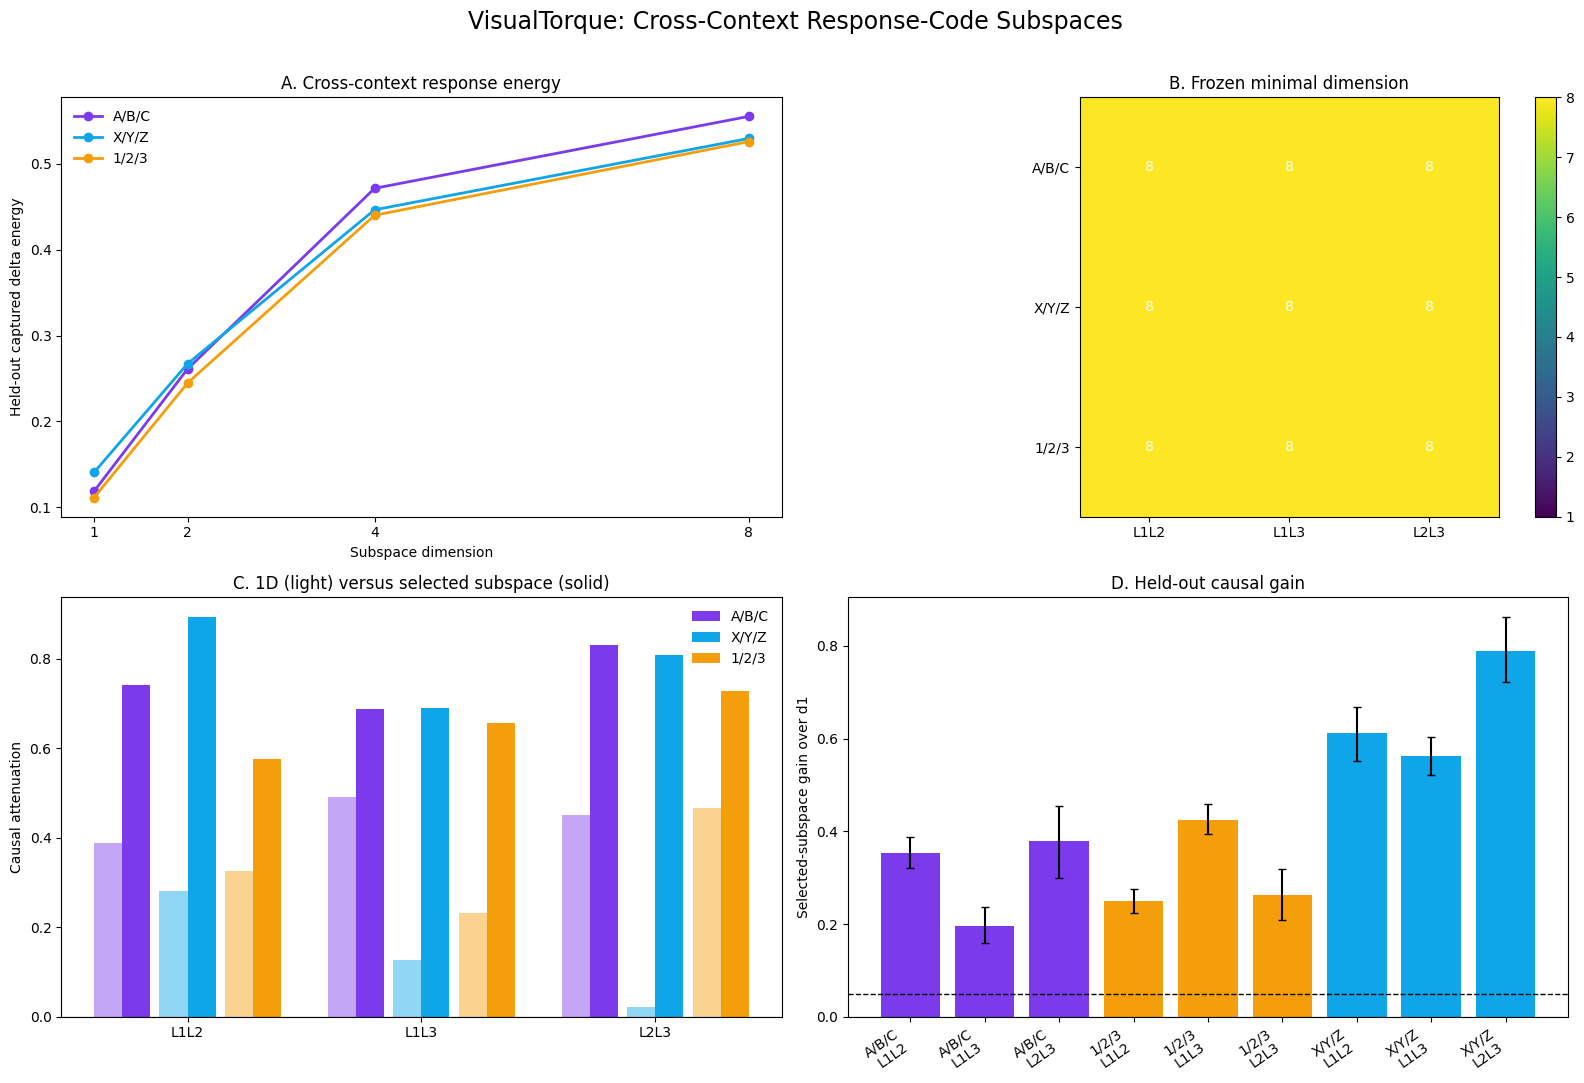

Figure: /content/drive/MyDrive/VisualTorque/results/qwen27b_cross_context_response_subspace_v1/analysis/figures/cross_context_response_subspaces.png


In [19]:
%%cell_progress 18/19 Save the paper-facing subspace figure
cell_stage('Rendering geometry, selection, causal gain, and controls')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
colors = {'abc': '#7C3AED', 'xyz': '#0EA5E9', 'digits': '#F59E0B'}
labels = {'abc': 'A/B/C', 'xyz': 'X/Y/Z', 'digits': '1/2/3'}

for codebook_key in CODEBOOKS:
    current = geometry_frame[geometry_frame['codebook'] == codebook_key]
    means = current.groupby('dimension')['heldout_energy'].mean().reindex(CANDIDATE_DIMS)
    axes[0, 0].plot(
        CANDIDATE_DIMS, means, marker='o', linewidth=2,
        color=colors[codebook_key], label=labels[codebook_key],
    )
axes[0, 0].set_xticks(CANDIDATE_DIMS)
axes[0, 0].set_xlabel('Subspace dimension')
axes[0, 0].set_ylabel('Held-out captured delta energy')
axes[0, 0].set_title('A. Cross-context response energy')
axes[0, 0].legend(frameon=False)

selected_matrix = pd.DataFrame(SELECTED_DIM).T.reindex(
    index=CODEBOOKS, columns=ORDINAL_PAIRS
)
image = axes[0, 1].imshow(selected_matrix.to_numpy(), cmap='viridis', vmin=1, vmax=8)
axes[0, 1].set_xticks(range(3), ORDINAL_PAIRS)
axes[0, 1].set_yticks(range(3), [labels[key] for key in CODEBOOKS])
for row_index in range(3):
    for column_index in range(3):
        value = int(selected_matrix.iloc[row_index, column_index])
        axes[0, 1].text(column_index, row_index, str(value), ha='center', va='center', color='white')
axes[0, 1].set_title('B. Frozen minimal dimension')
fig.colorbar(image, ax=axes[0, 1], fraction=0.046)

pair_means = pair_frame.groupby(['codebook', 'pair'])[[
    'attenuation_1d', 'attenuation_selected'
]].mean()
x = np.arange(len(ORDINAL_PAIRS))
width = 0.12
for book_index, codebook_key in enumerate(CODEBOOKS):
    one = pair_means.loc[codebook_key]['attenuation_1d'].reindex(ORDINAL_PAIRS)
    selected = pair_means.loc[codebook_key]['attenuation_selected'].reindex(ORDINAL_PAIRS)
    offset = (book_index - 1) * 0.28
    axes[1, 0].bar(
        x + offset - width / 2, one, width,
        color=colors[codebook_key], alpha=0.45,
    )
    axes[1, 0].bar(
        x + offset + width / 2, selected, width,
        color=colors[codebook_key], alpha=1.0,
        label=labels[codebook_key],
    )
axes[1, 0].axhline(0, color='black', linewidth=0.8)
axes[1, 0].set_xticks(x, ORDINAL_PAIRS)
axes[1, 0].set_ylabel('Causal attenuation')
axes[1, 0].set_title('C. 1D (light) versus selected subspace (solid)')
axes[1, 0].legend(frameon=False)

gain_rows = tests_frame[
    (tests_frame['test_family'] == 'pair')
    & (tests_frame['metric'] == 'multidim_gain')
].copy()
gain_rows['label'] = gain_rows['codebook'].map(labels) + '\n' + gain_rows['pair']
means = gain_rows['mean'].to_numpy(float)
low = means - gain_rows['ci_low'].to_numpy(float)
high = gain_rows['ci_high'].to_numpy(float) - means
axes[1, 1].bar(
    range(len(gain_rows)), means,
    color=[colors[key] for key in gain_rows['codebook']],
)
axes[1, 1].errorbar(
    range(len(gain_rows)), means, yerr=[low, high],
    fmt='none', color='black', capsize=3,
)
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].axhline(TARGET_GAIN_SESOI, color='black', linestyle='--', linewidth=1)
axes[1, 1].set_xticks(
    range(len(gain_rows)), gain_rows['label'], rotation=35, ha='right'
)
axes[1, 1].set_ylabel('Selected-subspace gain over d1')
axes[1, 1].set_title('D. Held-out causal gain')

fig.suptitle('VisualTorque: Cross-Context Response-Code Subspaces', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.97))
figure_path = FIGURE_DIR / 'cross_context_response_subspaces.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Figure:', figure_path)


In [20]:
%%cell_progress 19/19 Write the result card, paper tables, and run manifest
cell_stage('Saving interpretation, limitations, tables, and hashes')

interpretations = {
    'l1l2_positive_control_failed': (
        'The preregistered L1–L2 one-dimensional positive control did not '
        'replicate, so higher-dimensional results are not interpreted.'
    ),
    'no_context_invariant_low_dimensional_subspace': (
        'No candidate dimension through d8 passed the independent geometry '
        'criteria. The response route is not captured by a fixed low-dimensional '
        'subspace under these contexts.'
    ),
    'one_dimensional_response_routes_sufficient': (
        'Independent direction validation selected one dimension throughout; '
        'the prior instability was sampling noise rather than missing dimensions.'
    ),
    'multidimensional_response_subspaces_causally_supported': (
        'Independently selected multi-dimensional response subspaces reproduce '
        'across prompt contexts and causally block more semantic transport than '
        'their first direction and matched random subspaces.'
    ),
    'pair_specific_mixed_dimensional_routing': (
        'Some code pairs require reproducible multi-dimensional response routes '
        'with held-out causal gain, while other pairs remain one-dimensional or unstable.'
    ),
    'multidimensional_geometry_not_causally_needed': (
        'Multi-dimensional geometry is reproducible, but removing the additional '
        'dimensions does not improve causal blocking beyond the first direction.'
    ),
    'higher_dimension_does_not_stabilize_response_routes': (
        'Increasing dimension through d8 does not produce a reproducible selected '
        'subspace. The L55 response route is likely more strongly context-gated.'
    ),
}
decision_payload['interpretation'] = interpretations[
    decision_payload['primary_decision']
]
decision_payload['geometry_selection'] = selection_payload
decision_payload['audit'] = audit_payload
decision_payload['limitations'] = [
    'Only Qwen-27B and the L49-to-L55 final-prompt-token route are tested.',
    'Candidate dimensions stop at eight; a larger or nonlinear representation may still exist.',
    'Direction prompts use two balanced option orders per family rather than all six within every family.',
    'Target scenes are reused from the prior confirmation split, but the subspace intervention is new and dimensions are selected without target outputs.',
    'The result concerns downstream answer coding rather than upstream torque computation.',
]
decision_payload['completed_at_utc'] = datetime.now(timezone.utc).isoformat()
write_json_atomic(ANALYSIS_DIR / 'subspace_decision.json', decision_payload)

pair_summary = cell_frame.groupby(['codebook', 'pair']).agg(
    n=('family_id', 'size'),
    selected_dimension=('selected_dimension', 'first'),
    selection_pass=('selection_pass', 'first'),
    total_effect=('effect_total', 'mean'),
    attenuation_1d=('attenuation_1d', 'mean'),
    attenuation_selected=('attenuation_selected', 'mean'),
    specificity_selected=('specificity_selected', 'mean'),
    multidim_gain=('multidim_gain', 'mean'),
).reset_index()
pair_summary.to_csv(ANALYSIS_DIR / 'paper_pair_subspace_table.csv', index=False)

report_lines = [
    '# Cross-Context Response-Code Subspaces', '',
    f"- Decision: **{decision_payload['primary_decision']}**",
    f"- L1–L2 positive control: {decision_payload['positive_control_pass']}",
    f"- Stable multi-dimensional pairs: {decision_payload['stable_multidimensional_pairs']}",
    f"- Pairs with held-out causal gain: {decision_payload['causal_gain_pairs']}",
    '', '## Interpretation', '', decision_payload['interpretation'],
    '', '## Limitations', '',
]
report_lines.extend(f'- {value}' for value in decision_payload['limitations'])
(ANALYSIS_DIR / 'REPORT.md').write_text(
    '\n'.join(report_lines) + '\n', encoding='utf-8'
)

deliverables = sorted(
    path for path in ANALYSIS_DIR.rglob('*') if path.is_file()
)
run_manifest = {
    'schema_version': 'cross-context-response-subspace-run-manifest-1.0',
    'protocol_identity': canonical_protocol_identity,
    'support_identity': support_identity,
    'direction_capture_sha256': DIRECTION_CAPTURE_SHA256,
    'subspace_tensor_sha256': SUBSPACE_TENSOR_SHA256,
    'target_capture_sha256': TARGET_CAPTURE_SHA256,
    'primary_decision': decision_payload['primary_decision'],
    'deliverables': [{
        'path': str(path.relative_to(PROJECT_ROOT)),
        'sha256': sha256_file(path),
        'bytes': path.stat().st_size,
    } for path in deliverables],
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
}
write_json_atomic(SHARED_ROOT / 'RUN_COMPLETE.json', run_manifest)
display(pair_summary.round(4))
display(decision_payload)
print('Run complete:', SHARED_ROOT / 'RUN_COMPLETE.json')
print('Decision:', decision_payload['primary_decision'])


Write the result card, paper tables, and run manifest:  95%|#########4| 18/19 [00:00<?, ?cell/s]

,codebook,pair,n,selected_dimension,selection_pass,total_effect,attenuation_1d,attenuation_selected,specificity_selected,multidim_gain
0,abc,L1L2,48,8,True,0.7057,0.3880,0.7422,0.7526,0.3542
1,abc,L1L3,48,8,True,0.7266,0.4922,0.6875,0.6771,0.1953
2,abc,L2L3,48,8,True,0.8385,0.4505,0.8307,0.8177,0.3802
3,digits,L1L2,48,8,True,0.5938,0.3255,0.5755,0.5677,0.2500
4,digits,L1L3,48,8,True,0.7135,0.2318,0.6563,0.6224,0.4245
5,digits,L2L3,48,8,True,0.7344,0.4661,0.7292,0.7135,0.2630
6,xyz,L1L2,48,8,True,0.8672,0.2812,0.8932,0.8750,0.6120
7,xyz,L1L3,48,8,True,0.7760,0.1276,0.6901,0.6979,0.5625
8,xyz,L2L3,48,8,True,0.8802,0.0208,0.8099,0.7474,0.7891


{'schema_version': 'cross-context-response-subspace-decision-1.0',
 'model_id': 'Qwen/Qwen3.5-27B',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'primary_decision': 'multidimensional_response_subspaces_causally_supported',
 'positive_control_pass': True,
 'selected_dim': {'abc': {'L1L2': 8, 'L1L3': 8, 'L2L3': 8},
  'xyz': {'L1L2': 8, 'L1L3': 8, 'L2L3': 8},
  'digits': {'L1L2': 8, 'L1L3': 8, 'L2L3': 8}},
 'selection_pass': {'abc': {'L1L2': True, 'L1L3': True, 'L2L3': True},
  'xyz': {'L1L2': True, 'L1L3': True, 'L2L3': True},
  'digits': {'L1L2': True, 'L1L3': True, 'L2L3': True}},
 'multidimensional_pairs': [['abc', 'L1L2'],
  ['abc', 'L1L3'],
  ['abc', 'L2L3'],
  ['xyz', 'L1L2'],
  ['xyz', 'L1L3'],
  ['xyz', 'L2L3'],
  ['digits', 'L1L2'],
  ['digits', 'L1L3'],
  ['digits', 'L2L3']],
 'stable_multidimensional_pairs': [['abc', 'L1L2'],
  ['abc', 'L1L3'],
  ['abc', 'L2L3'],
  ['xyz', 'L1L2'],
  ['xyz', 'L1L3'],
  ['xyz', 'L2L3'],
  ['digits', 'L1L2'],
  ['digits', '

Run complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_cross_context_response_subspace_v1/RUN_COMPLETE.json
Decision: multidimensional_response_subspaces_causally_supported
